# **04 RQ1: GDP Marine Heatwave Detection and Model Evaluation**
RQ1: This notebook compares two GDP SST-based warm-condition detection models against an OISST marine heatwave reference for the 2013–2016 Blob and 2019–2020 event.

**Model A**: GDP SST exceeds the historical local OISST mean by 1°C.
**Model B**: GDP SST exceeds the historical local OISST 90th percentile.
Reference: OISST exceeds its historical P90 threshold for at least five consecutive days.

**Inputs**: processed GDP Zarr dataset, historical OISST climatology, and event-year OISST NetCDF files.
**Outputs**: OISST MHW reference dataset, evaluation tables, spatial comparisons, confusion matrices and threshold-tuning figure.

**Baseline**: The loaded climatology file is labelled 1982–2011. Confirm that this agrees with the final report.

## 1. Setup and dependencies

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

climatology = xr.open_dataset(
    "../data/processed/oisst_climatology_1982_2011.nc"
)

## 2. Load the processed GDP dataset

In [2]:
# load processed GDP dataset
ds = xr.open_zarr(
    "../data/processed/california_current_new.zarr"
)

## 3. Filter GDP Observations
Retain SST quality flag 5, convert Kelvin to Celsius, and select the two study events.

In [3]:
# extract high-quality GDP observations

gdp = pd.DataFrame({
    "time": pd.to_datetime(ds["time"].values),
    "lat": ds["lat"].values,
    "lon": ds["lon"].values,
    "sst": ds["sst"].values,
    "flg_sst": ds["flg_sst"].values
})

# keep high-quality SST measurements
gdp = gdp[gdp["flg_sst"] == 5].copy()

# convert Kelvin to Celsius
gdp["sst_c"] = gdp["sst"] - 273.15

# keep observations during the two events
event_mask = (
    gdp["time"].between("2013-01-01", "2016-12-31 23:59:59")
    |
    gdp["time"].between("2019-01-01", "2020-12-31 23:59:59")
)

gdp = gdp[event_mask].copy()

print("Observations:", len(gdp))
print(gdp[["time", "lat", "lon", "sst_c"]].head())

Observations: 843941
                 time        lat         lon      sst_c
0 2013-06-08 09:00:00  46.073181 -134.991623  11.694000
1 2013-06-08 10:00:00  46.077641 -134.981186  11.675018
2 2013-06-08 11:00:00  46.069801 -134.971878  11.643005
3 2013-06-08 12:00:00  46.065510 -134.960922  11.610992
4 2013-06-08 13:00:00  46.059978 -134.951523  11.593018


## 4. Match GDP SST to historical OISST thresholds
Exclude February 29 from GDP calendar-day matching and use nearest OISST grid cells.

In [4]:
# match each drifter observation to its historical climatology
# for every GDP observation, identify its calendar day (1-365), 
# its nearest OISST grid location, its corresponding historical mean SST 
# and 90-th percentile threshold

# exclude February 29 for consistency with the climatology
gdp = gdp[
    ~(
        (gdp["time"].dt.month == 2) &
        (gdp["time"].dt.day == 29)
    )
].copy()

# use a non-leap year to construct a consistent calendar day
gdp["dayofyear"] = pd.to_datetime(
    "2001-" + gdp["time"].dt.strftime("%m-%d")
).dt.dayofyear

In [5]:
# match the nearest OISST grid cell using vectorised indexing
# OISST longitude is 0–360; GDP longitude may be -180–180
gdp["lon_360"] = gdp["lon"] % 360

# remove observations outside the climatology grid
gdp = gdp[
    gdp["lat"].between(
        float(climatology.lat.min()),
        float(climatology.lat.max())
    )
    &
    gdp["lon_360"].between(
        float(climatology.lon.min()),
        float(climatology.lon.max())
    )
].copy()

# reset index for positional matching
gdp = gdp.reset_index(drop=True)

day_idx = xr.DataArray(gdp["dayofyear"].to_numpy(), dims="obs")
lat_idx = xr.DataArray(gdp["lat"].to_numpy(), dims="obs")
lon_idx = xr.DataArray(gdp["lon_360"].to_numpy(), dims="obs")

matched = climatology.sel(
    dayofyear=day_idx,
    lat=lat_idx,
    lon=lon_idx,
    method="nearest"
)

gdp["historical_mean"] = matched["mean_sst"].values
gdp["historical_p90"] = matched["p90_sst"].values

## 5. Define the two GDP detection models
Model A: +1°C anomaly baseline

Model B: historical 90th percentile exceedance


In [6]:
# implement model A and B threshold flags

# Model A: simple +1°C anomaly baseline
gdp["sst_anomaly"] = (
    gdp["sst_c"] - gdp["historical_mean"]
)

gdp["model_a"] = gdp["sst_anomaly"] > 1.0

# Model B: historical 90th percentile exceedance
gdp["model_b_exceedance"] = (
    gdp["sst_c"] > gdp["historical_p90"]
)

print("Model A flagged:", gdp["model_a"].sum())
print("Model B exceedances:", gdp["model_b_exceedance"].sum())

Model A flagged: 440152
Model B exceedances: 402513


In [7]:
# proportion of observations flagged
print(
    "Model A:",
    round(gdp["model_a"].mean() * 100, 2),
    "% flagged"
)

print(
    "Model B threshold:",
    round(gdp["model_b_exceedance"].mean() * 100, 2),
    "% flagged"
)

Model A: 53.3 % flagged
Model B threshold: 48.74 % flagged


In [8]:
print("Final observations:", len(gdp))

print("Missing historical mean:",
      gdp["historical_mean"].isna().sum())

print("Missing historical P90:",
      gdp["historical_p90"].isna().sum())

print("Model A percentage:",
      gdp["model_a"].mean() * 100)

print("Model B percentage:",
      gdp["model_b_exceedance"].mean() * 100)

Final observations: 825756
Missing historical mean: 8
Missing historical P90: 8
Model A percentage: 53.30291272482428
Model B percentage: 48.74478659555607


## 6. Retain observations with valid historical thresholds

In [9]:
# remove the 8 missing observations without valid historical thresholds
gdp = gdp.dropna(
    subset=[
        "sst_c",
        "historical_mean",
        "historical_p90"
    ]
).copy()

print("Final valid observations:", len(gdp))

print("Model A flagged:", gdp["model_a"].sum())
print("Model B exceedances:", gdp["model_b_exceedance"].sum())

print("Model A percentage:", round(gdp["model_a"].mean() * 100, 2))
print("Model B percentage:", round(gdp["model_b_exceedance"].mean() * 100, 2))

Final valid observations: 825748
Model A flagged: 440152
Model B exceedances: 402513
Model A percentage: 53.3
Model B percentage: 48.75


## 7. Load event-year OISST and construct the five-day MHW reference
Note: February 29 uses the February 28 threshold so that consecutive calendar days are preserved.

In [10]:
from pathlib import Path

folder = Path("../data/processed/oisst_yearly")
event_years = [2013, 2014, 2015, 2016, 2019, 2020]

event_arrays = []

for year in event_years:
    path = folder / f"oisst_cc_{year}.nc"

    with xr.open_dataset(path) as ds:
        event_arrays.append(ds["sst"].load())

    print(f"{year}: loaded")

oisst_events = xr.concat(
    event_arrays,
    dim="time"
).sortby("time")

2013: loaded
2014: loaded
2015: loaded
2016: loaded
2019: loaded
2020: loaded


In [11]:
# keep February 29 to preserve consecutive calendar days
dates = pd.DatetimeIndex(oisst_events.time.values)

month_day = dates.strftime("%m-%d")

# use February 28's climatology threshold for February 29
month_day = np.where(
    month_day == "02-29",
    "02-28",
    month_day
)

dayofyear = pd.to_datetime(
    "2001-" + month_day
).dayofyear

day_index = xr.DataArray(
    dayofyear,
    dims="time",
    coords={"time": oisst_events.time}
)

daily_p90 = climatology["p90_sst"].sel(
    dayofyear=day_index
)

oisst_exceedance = oisst_events > daily_p90

In [12]:
print("Total exceedances:", int(oisst_exceedance.sum()))

print(
    "Exceedance percentage:",
    round(float(oisst_exceedance.mean()) * 100, 2),
    "%"
)

Total exceedances: 4428902
Exceedance percentage: 27.45 %


### Apply the five-consecutive-day definition

In [13]:
# implement a function that identifies all days belonging to 
# a run of at least five exceedances
def detect_mhw_5days(exceedance):

    # a five-day window is valid if every day exceeds P90
    complete_window = (
        exceedance
        .rolling(time=5, min_periods=5)
        .sum() == 5
    )

    # mark all five days belonging to each valid window
    event_days = xr.zeros_like(
        exceedance,
        dtype=bool
    )

    for offset in range(5):
        event_days = event_days | complete_window.shift(
            time=-offset,
            fill_value=False
        )

    return event_days

In [14]:
# apply the five-consecutive-day rule

# separate the two marine heatwave periods
blob_exceedance = oisst_exceedance.sel(
    time=slice("2013-01-01", "2016-12-31")
)

mhw2019_exceedance = oisst_exceedance.sel(
    time=slice("2019-01-01", "2020-12-31")
)

# apply the five-consecutive-day rule
blob_mhw = detect_mhw_5days(blob_exceedance)

mhw2019 = detect_mhw_5days(mhw2019_exceedance)

# check the results
print("2013–2016 Blob:")
print("Total days:", blob_mhw.sizes["time"])
print("MHW grid-cell days:", int(blob_mhw.sum()))

print("\n2019–2020 MHW:")
print("Total days:", mhw2019.sizes["time"])
print("MHW grid-cell days:", int(mhw2019.sum()))

2013–2016 Blob:
Total days: 1461
MHW grid-cell days: 2919475

2019–2020 MHW:
Total days: 731
MHW grid-cell days: 1086407


In [15]:
# identify grid-cell days with valid observed SST and P90 thresholds
valid_ocean = (
    oisst_events.notnull()
    & daily_p90.notnull()
)

# separate the valid ocean masks by event period
blob_valid = valid_ocean.sel(
    time=slice("2013-01-01", "2016-12-31")
)

mhw2019_valid = valid_ocean.sel(
    time=slice("2019-01-01", "2020-12-31")
)

# calculate MHW percentages using valid ocean grid-cell days
blob_percentage = (
    blob_mhw.sum() / blob_valid.sum()
) * 100

mhw2019_percentage = (
    mhw2019.sum() / mhw2019_valid.sum()
) * 100

print("2013–2016 Blob MHW percentage:",
      round(float(blob_percentage), 2), "%")

print("2019–2020 MHW percentage:",
      round(float(mhw2019_percentage), 2), "%")

2013–2016 Blob MHW percentage: 36.92 %
2019–2020 MHW percentage: 27.46 %


### Save the OISST reference dataset

In [16]:
# combine the two detected MHW periods
oisst_mhw_reference = xr.concat(
    [blob_mhw, mhw2019],
    dim="time"
).sortby("time")

# create a dataset containing both the threshold exceedances
# and the five-day marine heatwave classifications
reference_ds = xr.Dataset({
    "mhw_reference": oisst_mhw_reference,
    "sst_exceedance": oisst_exceedance
})

# save to processed data folder
output_path = "../data/processed/oisst_mhw_reference_2013_2020.nc"

reference_ds.to_netcdf(output_path)

print("Saved OISST reference dataset!")

Saved OISST reference dataset!


## 8. Match the OISST reference to GDP observations

In [17]:
# GDP vs OISST comparison

# step 1: match GDP observations to OISST marine heatwave classifications

gdp["date"] = gdp["time"].dt.normalize()

# prepare coordinates for matching
time_idx = xr.DataArray(
    gdp["date"].to_numpy(),
    dims="obs"
)

lat_idx = xr.DataArray(
    gdp["lat"].to_numpy(),
    dims="obs"
)

lon_idx = xr.DataArray(
    gdp["lon_360"].to_numpy(),
    dims="obs"
)

# match each drifter observation to its nearest OISST grid cell
matched_reference = reference_ds["mhw_reference"].sel(
    time=time_idx,
    lat=lat_idx,
    lon=lon_idx,
    method="nearest"
)

# add OISST classification to GDP dataframe
gdp["oisst_mhw"] = matched_reference.values

In [18]:
print("Total GDP observations:", len(gdp))

print("\nOISST reference classifications:")
print(gdp["oisst_mhw"].value_counts(dropna=False))

print("\nOISST MHW percentage at GDP locations:")
print(round(gdp["oisst_mhw"].mean() * 100, 2), "%")

Total GDP observations: 825748

OISST reference classifications:
oisst_mhw
False    488280
True     337468
Name: count, dtype: int64

OISST MHW percentage at GDP locations:
40.87 %


40.87% of GDP observations occured at locations and dates that OISST classified as marine heatwave conditions

Comparison with GDP detectors:
GDP Model A: 53.30%
GDP Model B: 48.75%
OISST reference: 40.87%

### Retain valid OISST comparisons

In [19]:
# identify valid SST and threshold values at the matched
# OISST grid cells for each GDP observation

matched_valid = valid_ocean.sel(
    time=time_idx,
    lat=lat_idx,
    lon=lon_idx,
    method="nearest"
)

gdp["oisst_valid"] = matched_valid.values

print("Valid OISST matches:")
print(gdp["oisst_valid"].value_counts(dropna=False))

print("\nInvalid matches:")
print((~gdp["oisst_valid"]).sum())

Valid OISST matches:
oisst_valid
True     825743
False         5
Name: count, dtype: int64

Invalid matches:
5


In [20]:
# keep only GDP observations with valid OISST reference data
gdp = gdp[gdp["oisst_valid"]].copy().reset_index(drop=True)

print("Final evaluation sample:", len(gdp))
print("OISST MHW observations:", gdp["oisst_mhw"].sum())

Final evaluation sample: 825743
OISST MHW observations: 337468


## 9. Evaluate Model A and Model B
Report precision, recall and F1 against the OISST five-day reference.

In [21]:
# Step 2: Calculate precision, recall and F1 scores
# compare the GDP temperature detectors with the OISST 
# five-day marine heatwave reference

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_true = gdp["oisst_mhw"]

results = []

for model_name, column in [
    ("Model A (+1°C)", "model_a"),
    ("Model B (P90 exceedance)", "model_b_exceedance")
]:
    y_pred = gdp[column]

    results.append({
        "Model": model_name,
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

                      Model  Precision  Recall     F1
0            Model A (+1°C)      0.723   0.944  0.819
1  Model B (P90 exceedance)      0.802   0.957  0.873


### Confusion-matrix counts of Model A and B
This only includes the counts of true/false positives/negatives of Models A and B, not the actual confusion matrices.

In [22]:
# calculate the true/false positives/negatives for each model

for model_name, column in [
    ("Model A (+1°C)", "model_a"),
    ("Model B (P90 exceedance)", "model_b_exceedance")
]:
    tn, fp, fn, tp = confusion_matrix(
        gdp["oisst_mhw"],
        gdp[column],
        labels=[False, True]
    ).ravel()

    print(f"\n{model_name}")
    print("True positives:", tp)
    print("False positives:", fp)
    print("False negatives:", fn)
    print("True negatives:", tn)


Model A (+1°C)
True positives: 318402
False positives: 121745
False negatives: 19066
True negatives: 366530

Model B (P90 exceedance)
True positives: 322966
False positives: 79542
False negatives: 14502
True negatives: 408733


### Event-specific evaluation

In [23]:
# evaluate models separately for each marine heatwave period

gdp["event_period"] = np.where(
    gdp["time"].dt.year.between(2013, 2016),
    "2013–2016 Blob",
    "2019–2020 MHW"
)

event_results = []

for event, group in gdp.groupby("event_period"):
    for model_name, column in [
        ("Model A", "model_a"),
        ("Model B", "model_b_exceedance")
    ]:
        event_results.append({
            "Event": event,
            "Model": model_name,
            "Observations": len(group),
            "Precision": precision_score(
                group["oisst_mhw"], group[column]
            ),
            "Recall": recall_score(
                group["oisst_mhw"], group[column]
            ),
            "F1": f1_score(
                group["oisst_mhw"], group[column]
            )
        })

event_results_df = pd.DataFrame(event_results)

print(event_results_df.round(3))

            Event    Model  Observations  Precision  Recall     F1
0  2013–2016 Blob  Model A        534212      0.736   0.956  0.832
1  2013–2016 Blob  Model B        534212      0.800   0.962  0.874
2   2019–2020 MHW  Model A        291531      0.691   0.911  0.786
3   2019–2020 MHW  Model B        291531      0.808   0.945  0.871


## 10. Monthly Detection Rates

In [24]:
# evaluate how GDP temperature detections change over time
# calculate monthly detection rates
gdp["month"] = gdp["time"].dt.to_period("M").dt.to_timestamp()

monthly_rates = (
    gdp.groupby("month")
    .agg(
        model_a=("model_a", "mean"),
        model_b=("model_b_exceedance", "mean"),
        oisst_mhw=("oisst_mhw", "mean"),
        observations=("sst_c", "size")
    )
)

# convert proportions to percentages
monthly_rates[["model_a", "model_b", "oisst_mhw"]] *= 100

print(monthly_rates.head(10).round(2))

            model_a  model_b  oisst_mhw  observations
month                                                
2013-01-01     1.15     2.90       1.16         13708
2013-02-01     0.04     0.04       0.00          7705
2013-03-01     1.32     1.48       0.00          4453
2013-04-01     7.89     3.31       0.00          2117
2013-05-01     9.31     5.97       0.00           988
2013-06-01    15.62     7.31       0.00          1504
2013-07-01    27.73    17.23       7.73          3790
2013-08-01    46.81    46.37      19.91          4841
2013-09-01    20.13    19.93      14.28          9514
2013-10-01     2.16     3.72       0.62         15474


### Figure: Monthly Detection-rate Graph for Model A and B (**Figure 1.4** in the Final Report)

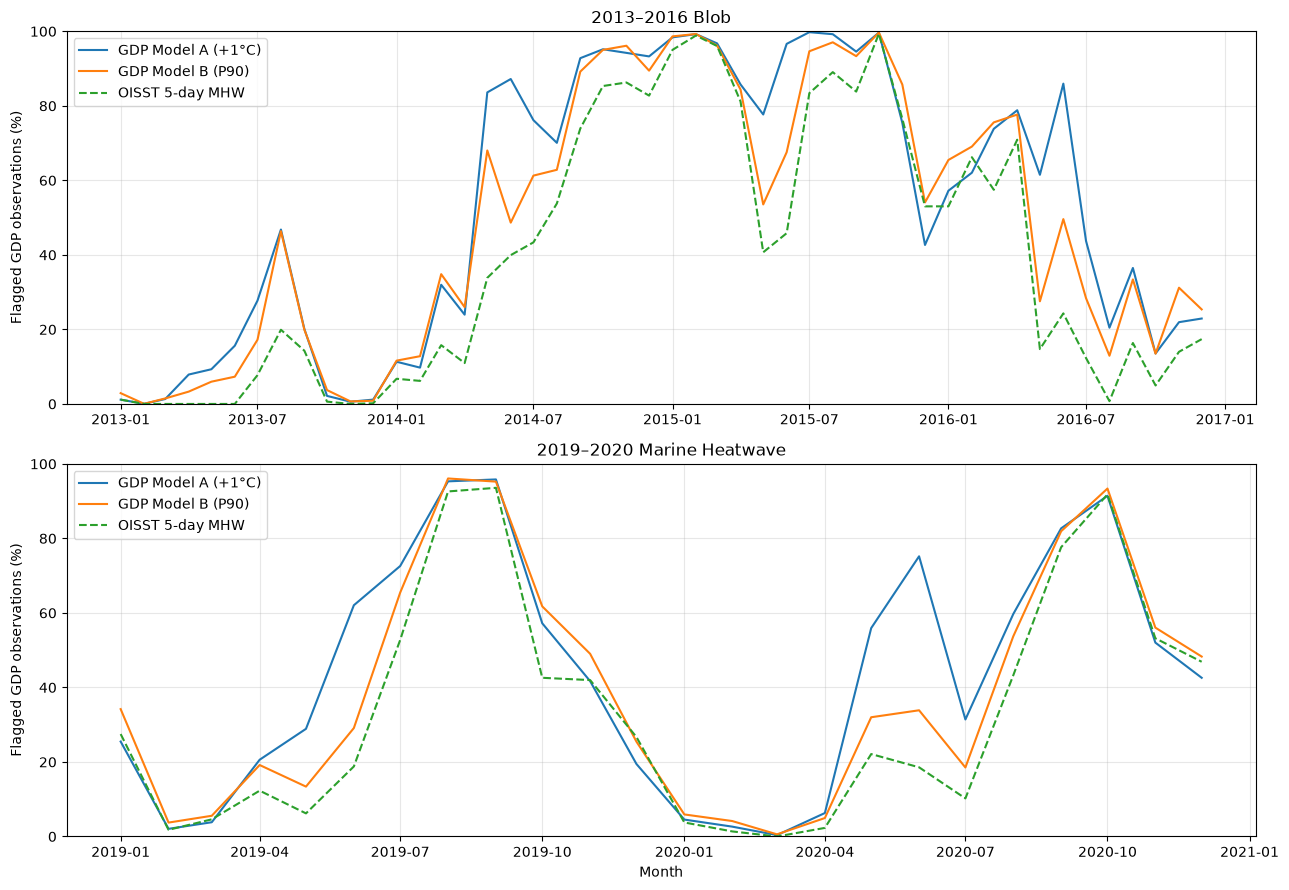

In [25]:
# plotting the monthly time series
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

periods = [
    ("2013-01-01", "2016-12-31", "2013–2016 Blob"),
    ("2019-01-01", "2020-12-31", "2019–2020 Marine Heatwave")
]

for ax, (start, end, title) in zip(axes, periods):

    data = monthly_rates.loc[start:end]

    ax.plot(
        data.index,
        data["model_a"],
        label="GDP Model A (+1°C)"
    )

    ax.plot(
        data.index,
        data["model_b"],
        label="GDP Model B (P90)"
    )

    ax.plot(
        data.index,
        data["oisst_mhw"],
        label="OISST 5-day MHW",
        linestyle="--"
    )

    ax.set_title(title)
    ax.set_ylabel("Flagged GDP observations (%)")
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Month")

plt.tight_layout()
plt.show()

*This is Figure 1.4 in the final report*

## 11. Recover drifter identifiers and assess sample coverage

In [26]:
# check the number of unique drifters

# reload the original GDP drifter dataset
gdp_ds = xr.open_zarr(
    "../data/processed/california_current_new.zarr"
)

In [27]:
# reconstruct the drifter ID for every original GDP observation
drifter_ids = np.repeat(
    gdp_ds["id"].values,
    gdp_ds["rowsize"].values.astype(int)
)

assert len(drifter_ids) == gdp_ds.sizes["obs"]

In [28]:
# reconstruct the original observation indices using time and position
original_gdp = pd.DataFrame({
    "time": pd.to_datetime(gdp_ds["time"].values),
    "lat": gdp_ds["lat"].values,
    "lon": gdp_ds["lon"].values,
    "drifter_id": drifter_ids
})

# match IDs using time and location
gdp = gdp.merge(
    original_gdp,
    on=["time", "lat", "lon"],
    how="left",
    validate="many_to_one"
)

print("Observations:", len(gdp))
print("Missing drifter IDs:", gdp["drifter_id"].isna().sum())
print("Unique drifters:", gdp["drifter_id"].nunique())

Observations: 825743
Missing drifter IDs: 0
Unique drifters: 202


### Monthly observation and drifter coverage

In [29]:
monthly_coverage = (
    gdp.groupby("month")
    .agg(
        observations=("sst_c", "size"),
        unique_drifters=("drifter_id", "nunique"),
        model_b_rate=("model_b_exceedance", "mean"),
        oisst_mhw_rate=("oisst_mhw", "mean")
    )
)

monthly_coverage[["model_b_rate", "oisst_mhw_rate"]] *= 100

## 12. Spatial comparisons during selected event months

### Figure: Spatial Map Comparison (**Figure 1.5** in the Final Report)
This makes the spatial maps for October 2014 and September 2019

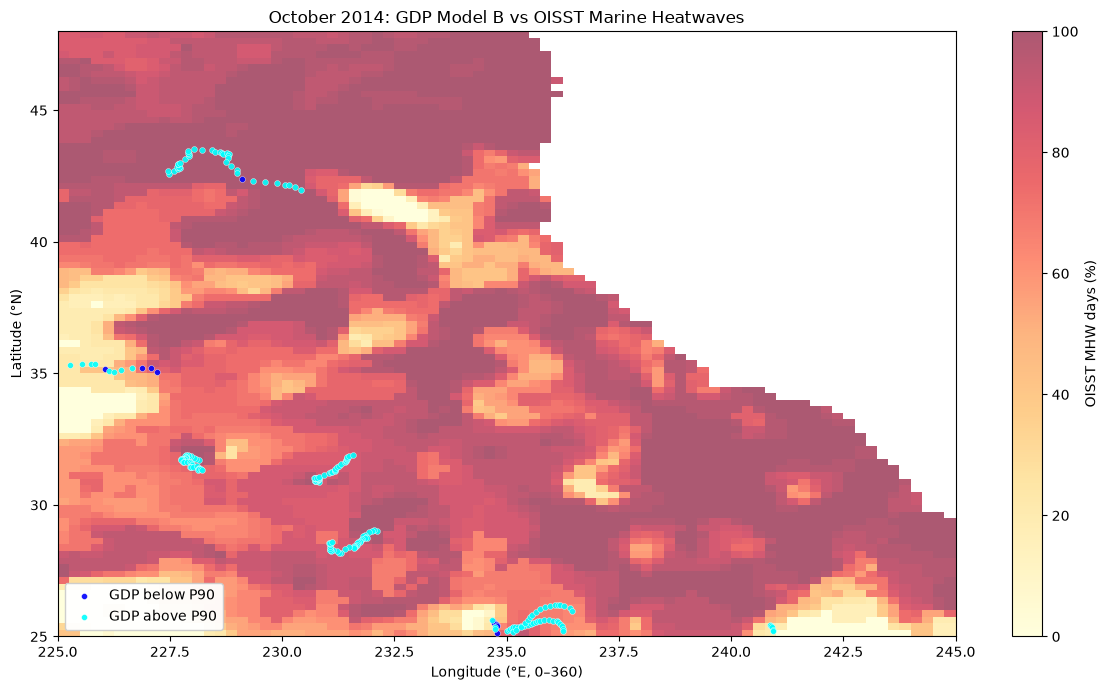

In [30]:
# create an OISST map with GDP detections overlaid

# spatial comparison: October 2014
month_start = "2014-10-01"
month_end = "2014-10-31"

# OISST: fraction of days classified as MHW at each grid cell
oisst_month = reference_ds["mhw_reference"].sel(
    time=slice(month_start, month_end)
)

oisst_valid_month = valid_ocean.sel(
    time=slice(month_start, month_end)
)

# percentage of valid days classified as MHW
oisst_spatial = (
    oisst_month.sum("time") /
    oisst_valid_month.sum("time")
) * 100

gdp_month = gdp[
    gdp["time"].between(month_start, "2014-10-31 23:59:59")
]

# plot
fig, ax = plt.subplots(figsize=(12, 7))

# OISST background
oisst_spatial.plot(
    ax=ax,
    x="lon",
    y="lat",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    alpha=0.65,
    cbar_kwargs={"label": "OISST MHW days (%)"}
)

# plot every 20th GDP observation
gdp_plot = gdp_month.iloc[::20]

# GDP below threshold
ax.scatter(
    gdp_plot.loc[~gdp_plot["model_b_exceedance"], "lon_360"],
    gdp_plot.loc[~gdp_plot["model_b_exceedance"], "lat"],
    s=18,
    color="blue",
    edgecolors="white",
    linewidths=0.3,
    alpha=0.9,
    zorder=5,
    label="GDP below P90"
)

# GDP above threshold
ax.scatter(
    gdp_plot.loc[gdp_plot["model_b_exceedance"], "lon_360"],
    gdp_plot.loc[gdp_plot["model_b_exceedance"], "lat"],
    s=18,
    color="cyan",
    edgecolors="white",
    linewidths=0.3,
    alpha=0.9,
    zorder=6,
    label="GDP above P90"
)

ax.set_title(
    "October 2014: GDP Model B vs OISST Marine Heatwaves"
)
ax.set_xlabel("Longitude (°E, 0–360)")
ax.set_ylabel("Latitude (°N)")

ax.legend(
    loc="lower left",
    facecolor="white",
    framealpha=0.95
)

plt.tight_layout()
plt.show()

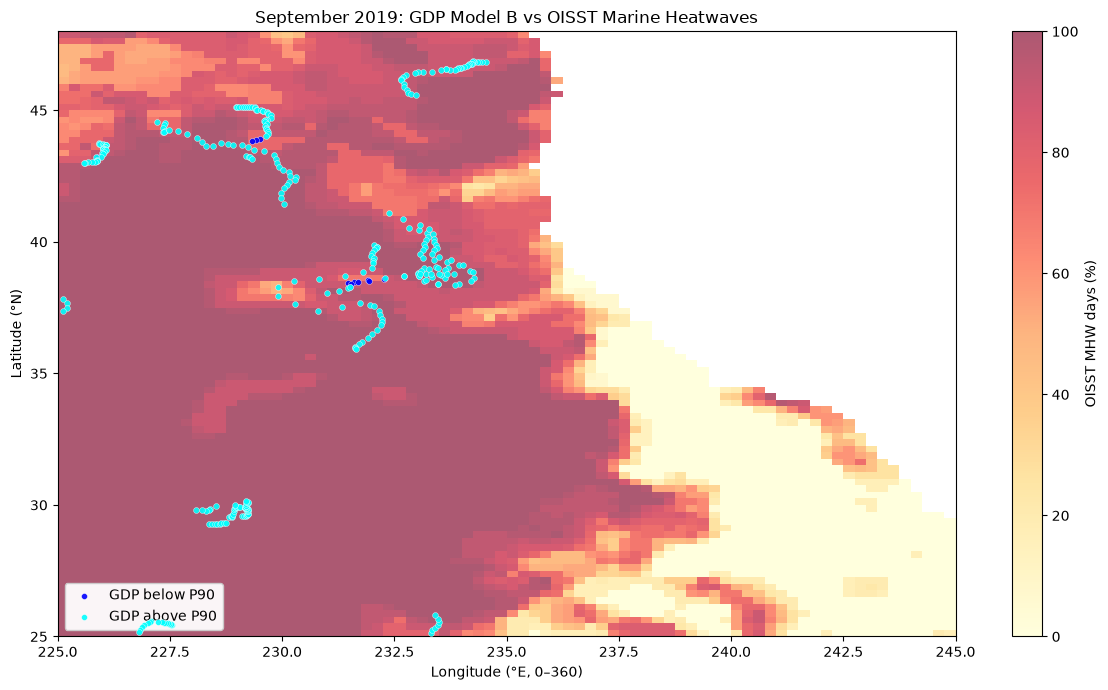

September 2019 observations: 6785
Unique drifters: 13
Model B exceedance rate: 95.24 %


In [31]:
# GDP Model B vs OISST Spatial Distribition on September 2019

month_start_2019 = "2019-09-01"
month_end_2019 = "2019-09-30"

oisst_month_2019 = reference_ds["mhw_reference"].sel(
    time=slice(month_start_2019, month_end_2019)
)

oisst_valid_month_2019 = valid_ocean.sel(
    time=slice(month_start_2019, month_end_2019)
)

# percentage of valid days classified as MHW
oisst_spatial_2019 = (
    oisst_month_2019.sum("time") /
    oisst_valid_month_2019.sum("time")
) * 100

# select GDP observations for September 2019
gdp_month_2019 = gdp[
    gdp["time"].between(
        month_start_2019,
        "2019-09-30 23:59:59"
    )
].copy()

# create spatial map
fig_2019, ax_2019 = plt.subplots(figsize=(12, 7))

# OISST background
oisst_spatial_2019.plot(
    ax=ax_2019,
    x="lon",
    y="lat",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    alpha=0.65,
    cbar_kwargs={"label": "OISST MHW days (%)"}
)

# plot every 20th GDP observation
gdp_plot_2019 = gdp_month_2019.iloc[::20]

# GDP observations below threshold
ax_2019.scatter(
    gdp_plot_2019.loc[
        ~gdp_plot_2019["model_b_exceedance"], "lon_360"
    ],
    gdp_plot_2019.loc[
        ~gdp_plot_2019["model_b_exceedance"], "lat"
    ],
    s=18,
    color="blue",
    edgecolors="white",
    linewidths=0.3,
    alpha=0.9,
    zorder=5,
    label="GDP below P90"
)

# GDP observations above threshold
ax_2019.scatter(
    gdp_plot_2019.loc[
        gdp_plot_2019["model_b_exceedance"], "lon_360"
    ],
    gdp_plot_2019.loc[
        gdp_plot_2019["model_b_exceedance"], "lat"
    ],
    s=18,
    color="cyan",
    edgecolors="white",
    linewidths=0.3,
    alpha=0.9,
    zorder=6,
    label="GDP above P90"
)

# labels and formatting
ax_2019.set_title(
    "September 2019: GDP Model B vs OISST Marine Heatwaves"
)

ax_2019.set_xlabel("Longitude (°E, 0–360)")
ax_2019.set_ylabel("Latitude (°N)")

ax_2019.legend(
    loc="lower left",
    facecolor="white",
    framealpha=0.95
)

plt.tight_layout()
plt.show()

# check September 2019 coverage
print("September 2019 observations:", len(gdp_month_2019))
print(
    "Unique drifters:",
    gdp_month_2019["drifter_id"].nunique()
)
print(
    "Model B exceedance rate:",
    round(gdp_month_2019["model_b_exceedance"].mean() * 100, 2),
    "%"
)

## 13. Figure: Model Confusion Matrices (**Figure 1.1** in the Final Report)

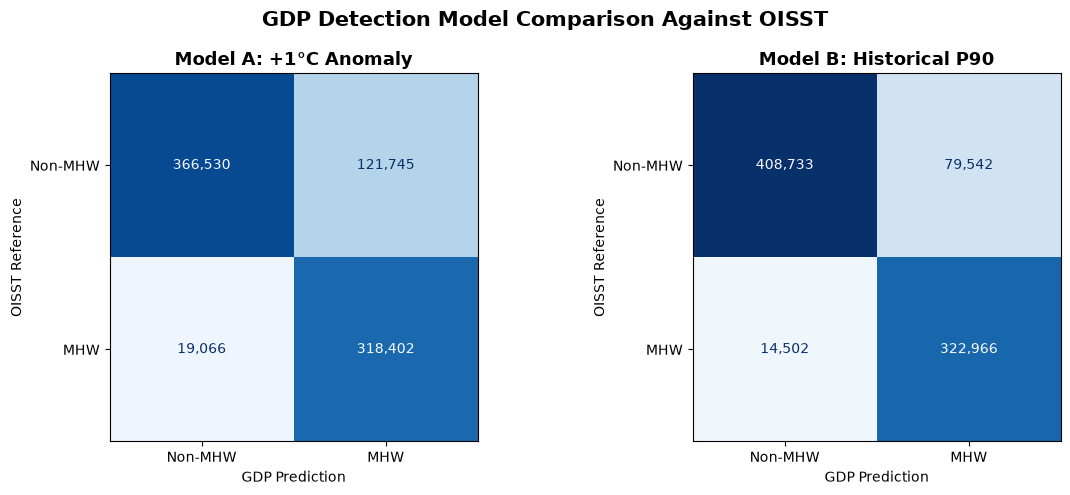

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# OISST 5-day MHW reference
y_true = gdp["oisst_mhw"].astype(bool)

# GDP model predictions
y_pred_a = gdp["model_a"].astype(bool)
y_pred_b = gdp["model_b_exceedance"].astype(bool)

# calculate confusion matrices
cm_a = confusion_matrix(y_true, y_pred_a, labels=[False, True])
cm_b = confusion_matrix(y_true, y_pred_b, labels=[False, True])

# create side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Model A: +1°C Anomaly", cm_a),
    ("Model B: Historical P90", cm_b)
]

for ax, (title, cm) in zip(axes, models):
    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-MHW", "MHW"]
    )

    cm_display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format=",d",
        im_kw={"vmin": 0, "vmax": max(cm_a.max(), cm_b.max())}
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("GDP Prediction")
    ax.set_ylabel("OISST Reference")

plt.suptitle(
    "GDP Detection Model Comparison Against OISST",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

*This is figure 1.1 in the final report.*

## 14. Historical OISST trend and sensitivity analysis (**Figures 1.7–1.10** in Final Report)


#### Setup

In [33]:
from scipy.ndimage import uniform_filter1d
from sklearn.metrics import f1_score
import calendar
import warnings

rq1_output = Path("../figures")
rq1_output.mkdir(parents=True, exist_ok=True)
BASE_START, BASE_END = 1982, 2011
baseline_files = [Path("../data/processed/oisst_yearly") / f"oisst_cc_{y}.nc"
                  for y in range(BASE_START, BASE_END + 1)]
missing_baseline = [str(f) for f in baseline_files if not f.exists()]
if missing_baseline:
    raise FileNotFoundError("Historical yearly OISST files required for Figure 1.7–1.13. "
                            f"Missing: {missing_baseline[:3]} (and {max(0,len(missing_baseline)-3)} more). "
                            "Re-run Notebook 03's historical download step.")

# the existing climatology is the single source of historical thresholds.
rq1_mean = climatology["sst_mean"] if "sst_mean" in climatology else climatology["mean_sst"]
rq1_p90 = climatology["sst_p90"] if "sst_p90" in climatology else climatology["p90_sst"]
print("Historical baseline: 1982–2011; event period: 2013–2016 and 2019–2020")

Historical baseline: 1982–2011; event period: 2013–2016 and 2019–2020


#### Figure 1.7: Area-weighted annual mean OISST and historical linear trend

C:\Users\ivory\AppData\Local\Temp\ipykernel_35376\54033473.py:44: RuntimeWarning: Mean of empty slice
  np.nanmean(monthly[months == m], axis=0)


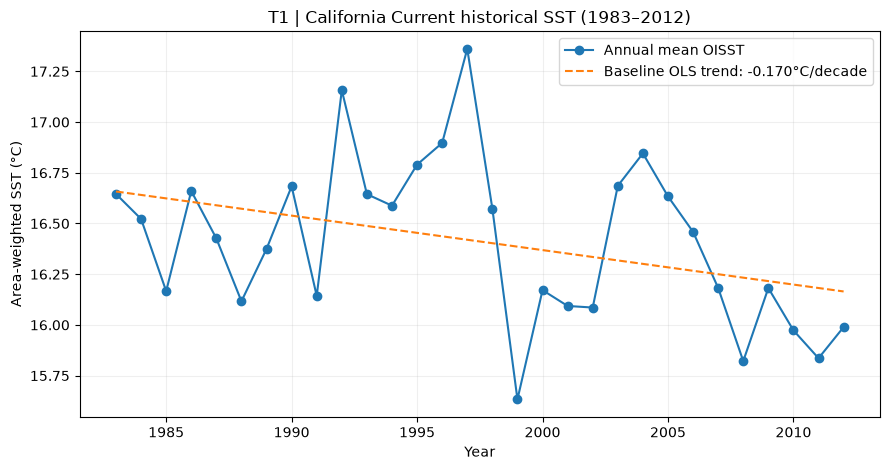

Baseline: 1983–2012
OLS trend: -0.170 °C/decade
2008 annual SST: 15.822 °C


In [45]:
# Figure 1.7 — Historical SST trend (1983–2012)

FIG_START, FIG_END = 1983, 2012
FIG_DIR = Path("../data/processed/oisst_yearly")

monthly_list = []
month_years = []
month_nums = []

for year in range(FIG_START, FIG_END + 1):
    path = FIG_DIR / f"oisst_cc_{year}.nc"

    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

    with xr.open_dataset(path) as ds:
        da = ds["sst"].transpose("time", "lat", "lon").load()

    for month in range(1, 13):
        month_da = da.where(
            da.time.dt.month == month,
            drop=True
        )

        monthly_list.append(
            month_da.mean("time", skipna=True).values
        )
        month_years.append(year)
        month_nums.append(month)

monthly = np.stack(monthly_list).astype("float64")
years = np.asarray(month_years)
months = np.asarray(month_nums)

lat_grid = da["lat"].values
lon_grid = da["lon"].values
ny, nx = len(lat_grid), len(lon_grid)

# deseasonalise monthly SST
times = years + (months - 0.5) / 12
ref_year = times.mean()

monthly_climatology = np.stack([
    np.nanmean(monthly[months == m], axis=0)
    for m in range(1, 13)
])

y_anomaly = monthly - monthly_climatology[months - 1]

valid = np.isfinite(y_anomaly)
x = (times - ref_year)[:, None, None]

n = valid.sum(axis=0)
sx = np.where(valid, x, 0).sum(axis=0)
sy = np.where(valid, y_anomaly, 0).sum(axis=0)
sxx = np.where(valid, x*x, 0).sum(axis=0)
sxy = np.where(valid, x*y_anomaly, 0).sum(axis=0)

den = n*sxx - sx*sx

trend_c_per_year = np.divide(
    n*sxy - sx*sy,
    den,
    out=np.full((ny, nx), np.nan),
    where=(n >= 24) & (den > 0)
)

# same area weighting as teammate
weights = (
    np.cos(np.deg2rad(lat_grid))[:, None]
    * np.ones((1, nx))
)

valid_cells = np.isfinite(trend_c_per_year)
weights = np.where(valid_cells, weights, 0.0)

area_monthly = (
    np.nansum(monthly * weights, axis=(1, 2))
    / np.nansum(
        np.where(np.isfinite(monthly), weights, 0.0),
        axis=(1, 2)
    )
)

area_annual = pd.Series(area_monthly).groupby(years).mean()

line_slope, line_intercept = np.polyfit(
    area_annual.index,
    area_annual.values,
    1
)

# plot
fig, ax = plt.subplots(figsize=(9, 4.8))

ax.plot(
    area_annual.index,
    area_annual.values,
    "o-",
    label="Annual mean OISST"
)

ax.plot(
    area_annual.index,
    line_slope * area_annual.index + line_intercept,
    "--",
    label=f"Baseline OLS trend: {line_slope*10:+.3f}°C/decade"
)

ax.set(
    title="T1 | California Current historical SST (1983–2012)",
    xlabel="Year",
    ylabel="Area-weighted SST (°C)"
)

ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()

fig.savefig(
    rq1_output / "Figure_1_7_historical_SST_trend.png",
    dpi=200
)

plt.show()

print(f"Baseline: {FIG_START}–{FIG_END}")
print(f"OLS trend: {line_slope*10:+.3f} °C/decade")
print(f"2008 annual SST: {area_annual.loc[2008]:.3f} °C")


#### Calculate the gridded historical SST trend
Fit a linear trend to monthly, seasonally demeaned OISST at each grid cell. This trend is used for fixed-versus-adjusted reference sensitivity.

In [46]:
monthly_array = np.stack(monthly_fields).astype("float64")
monthly_year = np.asarray(monthly_year)
monthly_month = np.asarray(monthly_month)
monthly_times = monthly_year + (monthly_month - .5) / 12
trend_reference_year = float(monthly_times.mean())
month_clim = np.stack([np.nanmean(monthly_array[monthly_month == m], axis=0)
                       for m in range(1, 13)])
anomaly = monthly_array - month_clim[monthly_month-1]
valid = np.isfinite(anomaly)
x = (monthly_times - trend_reference_year)[:, None, None]
n = valid.sum(axis=0)
sx = np.where(valid, x, 0).sum(axis=0)
sy = np.where(valid, anomaly, 0).sum(axis=0)
sxx = np.where(valid, x*x, 0).sum(axis=0)
sxy = np.where(valid, x*anomaly, 0).sum(axis=0)
den = n*sxx - sx*sx
trend_c_per_year = np.divide(n*sxy - sx*sy, den,
                             out=np.full_like(sx, np.nan, dtype=float),
                             where=(n>=24) & (den>0))
trend_da = xr.DataArray(trend_c_per_year, dims=(lat_name,lon_name),
                        coords={lat_name:lat_grid,lon_name:lon_grid})
# Release large historical monthly arrays before continuing.
del monthly_array, monthly_fields, anomaly, valid, annual_fields, annual_stack


C:\Users\ivory\AppData\Local\Temp\ipykernel_35376\622709166.py:6: RuntimeWarning: Mean of empty slice
  month_clim = np.stack([np.nanmean(monthly_array[monthly_month == m], axis=0)


#### Figures 1.8–1.9 — Fixed and trend-adjusted OISST references

In [48]:
# keep all sensitivity columns in a separate copy, without overwriting gdp.
rq1_sens = gdp.copy()
rq1_sens["date"] = pd.to_datetime(rq1_sens["time"]).dt.normalize()
rq1_sens["event"] = np.where(rq1_sens["date"].dt.year <= 2016,
                                  "2013–2016 Blob", "2019–2020 MHW")
# the historical trend uses the same nearest grid cells as the original notebook.
lat_vals = rq1_sens["lat"].to_numpy()
lon_vals = np.mod(rq1_sens["lon"].to_numpy(), 360)
lat_index = np.abs(lat_grid[:,None] - lat_vals[None,:]).argmin(axis=0)
lon_index = np.abs(lon_grid[:,None] - lon_vals[None,:]).argmin(axis=0)
rq1_sens["slope_c_per_year"] = trend_c_per_year[lat_index, lon_index]

# match original GDP daily calendar mapping to climatology, including leap-day treatment.
event_dates = pd.DatetimeIndex(oisst_events.time.values).normalize()
# the existing reference is already on the event grid, and its time coordinate is authoritative.
reference_dates = pd.DatetimeIndex(oisst_mhw_reference.time.values).normalize()
if not event_dates.equals(reference_dates):
    raise ValueError("OISST event SST and saved reference have different time coordinates")

# compute the time-dependent adjusted threshold from the SAME historical P90 as Model B.
def decimal_year(dates):
    dates = pd.DatetimeIndex(dates)
    starts = pd.to_datetime(dates.year.astype(str) + "-01-01")
    ends = pd.to_datetime((dates.year+1).astype(str) + "-01-01")
    return dates.year.to_numpy() + ((dates-starts)/(ends-starts)).to_numpy()

event_offset = decimal_year(event_dates) - trend_reference_year
# align trend grid to the OISST event grid using labelled coordinates.
event_lat = "lat" if "lat" in oisst_events.dims else "latitude"
event_lon = "lon" if "lon" in oisst_events.dims else "longitude"
trend_on_event = trend_da.rename({lat_name:event_lat,lon_name:event_lon}).sel(
    {event_lat:oisst_events[event_lat], event_lon:oisst_events[event_lon]},method="nearest")
# reuse the actual daily threshold constructed earlier in Notebook 04.
if "daily_p90" not in globals():
    raise RuntimeError("daily_p90 from the existing OISST reference section is required")
adjusted_p90 = daily_p90 + xr.DataArray(event_offset, dims="time",coords={"time":oisst_events.time}) * trend_on_event
adjusted_exceedance = (oisst_events > adjusted_p90).fillna(False)
# the original notebook's five-day detector is applied separately to the two event windows.
blob_adjusted = detect_mhw_5days(adjusted_exceedance.sel(time=slice("2013-01-01","2016-12-31")))
mhw2019_adjusted = detect_mhw_5days(adjusted_exceedance.sel(time=slice("2019-01-01","2020-12-31")))
adjusted_reference = xr.concat([blob_adjusted,mhw2019_adjusted],dim="time").sortby("time")

# vectorized location/date matching on the same sample.
ref_at_gdp = adjusted_reference.sel(time=xr.DataArray(rq1_sens["date"].to_numpy(),dims="sample"),
    **{event_lat:xr.DataArray(lat_vals,dims="sample"),
       event_lon:xr.DataArray(lon_vals,dims="sample")},method="nearest")
rq1_sens["ref_fixed"] = rq1_sens["oisst_mhw"].astype(bool)
rq1_sens["ref_adjusted"] = ref_at_gdp.to_numpy().astype(bool)
rq1_sens["threshold_shift_c"] = rq1_sens["slope_c_per_year"] * (
    decimal_year(rq1_sens["date"]) - trend_reference_year)
rq1_sens["A_fixed"] = rq1_sens["model_a"].astype(bool)
rq1_sens["B_fixed"] = rq1_sens["model_b_exceedance"].astype(bool)
rq1_sens["A_adjusted"] = rq1_sens["sst_c"] > (
    rq1_sens["historical_mean"] + rq1_sens["threshold_shift_c"] + 1.0)
rq1_sens["B_adjusted"] = rq1_sens["sst_c"] > (
    rq1_sens["historical_p90"] + rq1_sens["threshold_shift_c"])
rq1_sens = rq1_sens.dropna(subset=["slope_c_per_year","historical_mean","historical_p90"])


### Figures 1.8–1.10: Model B sensitivity at 0%, 50%, 100%, 150%
GDP Model B uses individual threshold exceedances; OISST references apply the five-consecutive-day rule. The fixed reference stays constant, while the adjusted reference is recomputed at each trend factor.

In [51]:
from IPython.display import display

,event,reference,adjustment,observations,GDP_alert_pct,OISST_reference_pct,F1
0,2013–2016 Blob,Fixed OISST,0.0,534212,54.695,45.523,0.874
1,2013–2016 Blob,Adjusted OISST,0.0,534212,54.695,45.523,0.874
2,2019–2020 MHW,Fixed OISST,0.0,291531,37.842,32.340,0.871
3,2019–2020 MHW,Adjusted OISST,0.0,291531,37.842,32.340,0.871
4,2013–2016 Blob,Fixed OISST,0.5,534212,63.075,45.523,0.828
5,2013–2016 Blob,Adjusted OISST,0.5,534212,63.075,54.807,0.901
6,2019–2020 MHW,Fixed OISST,0.5,291531,48.681,32.340,0.792
7,2019–2020 MHW,Adjusted OISST,0.5,291531,48.681,43.841,0.891
8,2013–2016 Blob,Fixed OISST,1.0,534212,70.121,45.523,0.784
9,2013–2016 Blob,Adjusted OISST,1.0,534212,70.121,63.391,0.924


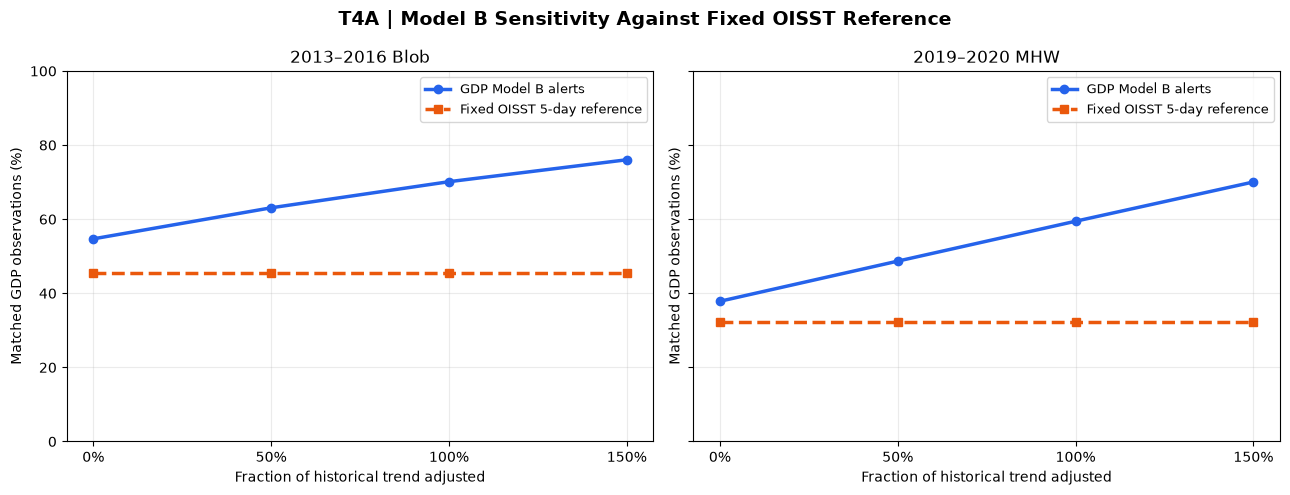

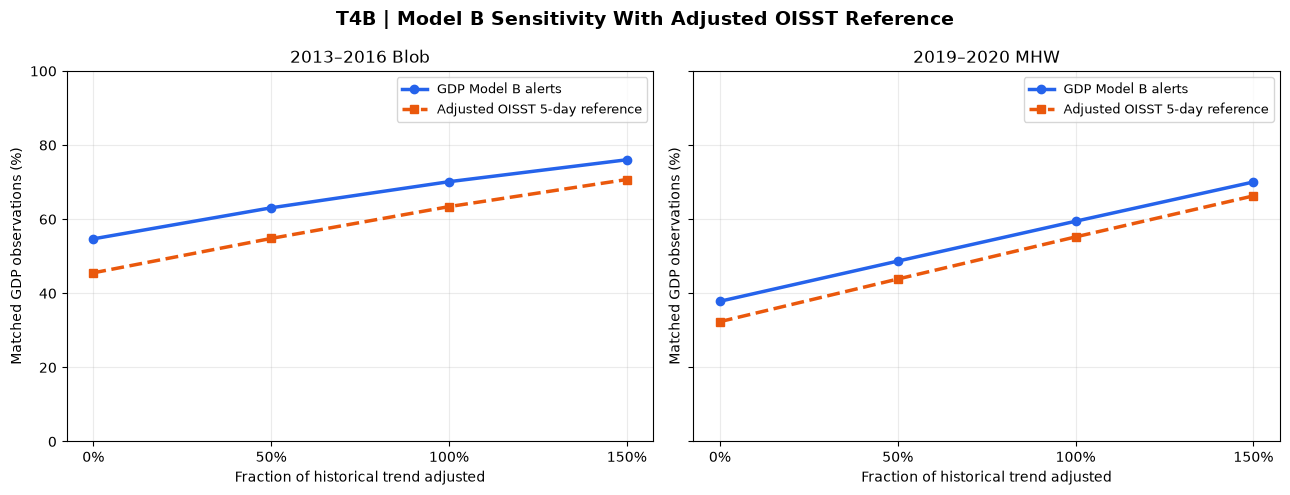

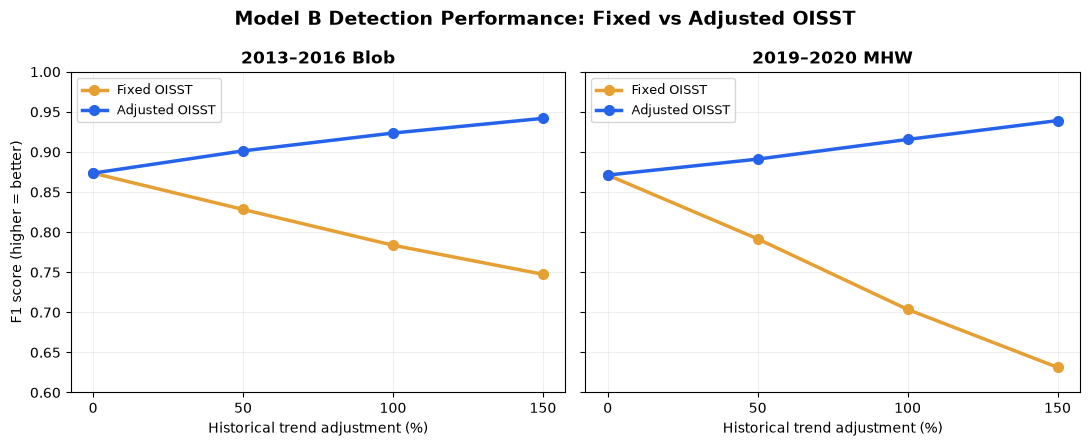

In [53]:
# T4 sensitivity: same GDP observations, Model B, and 5-day OISST references.
# Requires the preceding Figures 1.8–1.9 preparation cell.
from IPython.display import display

FACTORS_T4 = [0.0, 0.5, 1.0, 1.5]
EVENTS_T4 = ["2013–2016 Blob", "2019–2020 MHW"]

# Use the same observation sample for every comparison.
sample = rq1_sens.copy()
lat_sample = sample["lat"].to_numpy()
lon_sample = np.mod(sample["lon"].to_numpy(), 360)
sample_dates = sample["date"].to_numpy()

# The fixed reference is already matched to the GDP observations.
fixed_truth = sample["ref_fixed"].to_numpy(dtype=bool)
records = []

for factor in FACTORS_T4:
    # GDP Model B is a single-observation threshold exceedance (no 5-day rule).
    predicted = (
        sample["sst_c"].to_numpy() >
        sample["historical_p90"].to_numpy() +
        factor * sample["threshold_shift_c"].to_numpy()
    )

    # Adjust OISST's threshold and reapply the 5-consecutive-day criterion.
    threshold = daily_p90 + (
        factor * xr.DataArray(
            event_offset, dims="time", coords={"time": oisst_events.time}
        ) * trend_on_event
    )
    exceedance = (oisst_events > threshold).fillna(False)
    blob = detect_mhw_5days(exceedance.sel(time=slice("2013-01-01", "2016-12-31")))
    late = detect_mhw_5days(exceedance.sel(time=slice("2019-01-01", "2020-12-31")))
    adjusted_ref = xr.concat([blob, late], dim="time").sortby("time")

    adjusted_truth = adjusted_ref.sel(
        time=xr.DataArray(sample_dates, dims="sample"),
        **{
            event_lat: xr.DataArray(lat_sample, dims="sample"),
            event_lon: xr.DataArray(lon_sample, dims="sample")
        },
        method="nearest"
    ).to_numpy().astype(bool)

    for event in EVENTS_T4:
        keep = sample["event"].to_numpy() == event
        pred = predicted[keep]
        for reference_name, truth_all in (
            ("Fixed OISST", fixed_truth),
            ("Adjusted OISST", adjusted_truth),
        ):
            truth = truth_all[keep]
            tp = int(np.sum(pred & truth))
            fp = int(np.sum(pred & ~truth))
            fn = int(np.sum(~pred & truth))
            records.append({
                "event": event,
                "reference": reference_name,
                "adjustment": factor,
                "observations": int(keep.sum()),
                "GDP_alert_pct": 100 * pred.mean(),
                "OISST_reference_pct": 100 * truth.mean(),
                "F1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
            })

results_t4 = pd.DataFrame(records)
display(results_t4.round(3))

# Validate the expected invariants.
for event in EVENTS_T4:
    fixed = results_t4.query("event == @event and reference == 'Fixed OISST'")
    adjusted = results_t4.query("event == @event and reference == 'Adjusted OISST'")
    assert np.allclose(fixed["OISST_reference_pct"], fixed["OISST_reference_pct"].iloc[0])
    assert np.allclose(fixed["GDP_alert_pct"], adjusted["GDP_alert_pct"])

# Figure 1.8: Model B vs fixed OISST 5-day reference.
# Figure 1.9: Model B vs adjusted OISST 5-day reference.
def plot_t4(reference_name, figure_title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, event in zip(axes, EVENTS_T4):
        part = results_t4.loc[
            (results_t4["event"] == event) &
            (results_t4["reference"] == reference_name)
        ].sort_values("adjustment")
        x = part["adjustment"].to_numpy()
        ax.plot(x, part["GDP_alert_pct"], "o-", color="#2563EB",
                linewidth=2.5, label="GDP Model B alerts")
        ax.plot(x, part["OISST_reference_pct"], "s--", color="#EA580C",
                linewidth=2.5, label=f"{reference_name} 5-day reference")
        ax.set(title=event, xlabel="Fraction of historical trend adjusted",
               ylabel="Matched GDP observations (%)")
        ax.set_xticks(FACTORS_T4, ["0%", "50%", "100%", "150%"])
        ax.set_ylim(0, 100)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=9)
    fig.suptitle(figure_title, fontsize=14, fontweight="bold")
    fig.tight_layout()
    fig.savefig(rq1_output / filename, dpi=200, bbox_inches="tight")
    plt.show()

plot_t4("Fixed OISST", "T4A | Model B Sensitivity Against Fixed OISST Reference",
        "Figure_1_8_fixed_OISST.png")
plot_t4("Adjusted OISST", "T4B | Model B Sensitivity With Adjusted OISST Reference",
        "Figure_1_9_adjusted_OISST.png")

# Figure 1.10: F1 for both reference definitions at all four adjustments.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, event in zip(axes, EVENTS_T4):
    for reference_name, color in (("Fixed OISST", "#E69F33"),
                                  ("Adjusted OISST", "#2563EB")):
        part = results_t4.loc[
            (results_t4["event"] == event) &
            (results_t4["reference"] == reference_name)
        ].sort_values("adjustment")
        ax.plot(part["adjustment"] * 100, part["F1"], marker="o",
                linewidth=2.5, markersize=7, color=color, label=reference_name)
    ax.set_title(event, fontsize=12, fontweight="bold")
    ax.set_xlabel("Historical trend adjustment (%)")
    ax.set_xticks([0, 50, 100, 150])
    ax.set_ylim(0.6, 1.0)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
axes[0].set_ylabel("F1 score (higher = better)")
fig.suptitle("Model B Detection Performance: Fixed vs Adjusted OISST",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(rq1_output / "Figure_1_10_model_B_F1_sensitivity.png",
            dpi=300, bbox_inches="tight")
plt.show()
results_t4.to_csv(rq1_output / "T4_sensitivity_results.csv", index=False)


## 15. Threshold and duration robustness (**Figures 1.11–1.12** in Final Report)
P85/P95 require the historical daily SST values, not a shift applied to P90. The original 1982–2011 climatology remains the fixed P90 reference.

In [55]:
# historical P85/P95: ±5-day circular window, then 31-day circular smoothing.
# the original climatology has a 365-day seasonal index (Feb 29 excluded).
hist_arrays, hist_days = [], []
for year,path in zip(range(BASE_START,BASE_END+1),baseline_files):
    with xr.open_dataset(path) as source:
        da = source["sst"].squeeze(drop=True)
        dates = pd.DatetimeIndex(da.time.values)
        valid_dates = ~((dates.month==2)&(dates.day==29))
        hist_arrays.append(da.isel(time=np.flatnonzero(valid_dates)).values.astype("float32"))
        hist_days.append(pd.DatetimeIndex(dates[valid_dates]).dayofyear.to_numpy() -
                         (pd.DatetimeIndex(dates[valid_dates]).is_leap_year &
                          (pd.DatetimeIndex(dates[valid_dates]).month>2)).astype(int))
historical_sst = np.concatenate(hist_arrays,axis=0)
historical_doy = np.concatenate(hist_days)
percentile_grids = {}
for percentile in (85,95):
    raw = np.full((365,)+historical_sst.shape[1:],np.nan,dtype="float32")
    for day in range(1,366):
        delta = (historical_doy-day+182)%365-182
        with warnings.catch_warnings():
            warnings.simplefilter("ignore",RuntimeWarning)
            raw[day-1] = np.nanpercentile(historical_sst[np.abs(delta)<=5],percentile,axis=0)
    good = np.isfinite(raw).astype("float32")
    num = uniform_filter1d(np.nan_to_num(raw),31,axis=0,mode="wrap")
    den = uniform_filter1d(good,31,axis=0,mode="wrap")
    percentile_grids[percentile] = np.divide(num,den,out=np.full_like(raw,np.nan),where=den>0)
del historical_sst,hist_arrays

# attach P85/P95 to existing GDP sample using original nearest-grid locations.
seasonal_day = rq1_sens["date"].dt.dayofyear.to_numpy() - 1
seasonal_day -= (rq1_sens["date"].dt.is_leap_year & (rq1_sens["date"].dt.month>2)).to_numpy().astype(int)
seasonal_day = np.clip(seasonal_day,0,364)
robust_lat_ix=np.abs(lat_grid[:,None]-rq1_sens["lat"].to_numpy()[None,:]).argmin(axis=0)
robust_lon_ix=np.abs(lon_grid[:,None]-np.mod(rq1_sens["lon"].to_numpy(),360)[None,:]).argmin(axis=0)
for percentile in (85,95):
    rq1_sens[f"p{percentile}_c"] = percentile_grids[percentile][seasonal_day,robust_lat_ix,robust_lon_ix]


#### Figure 1.11: Model B threshold robustness (P85/P90/P95)

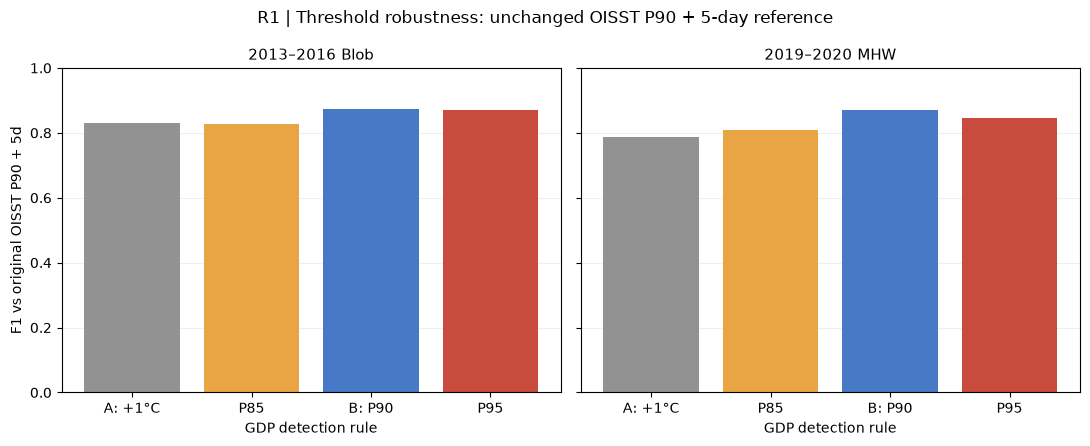

In [59]:
events = ["2013–2016 Blob", "2019–2020 MHW"]
labels = ["A: +1°C", "P85", "B: P90", "P95"]
colors = ["#929292", "#E9A443", "#4779C7", "#C94B3D"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

for ax, event in zip(axes, events):
    part = rq1_sens.loc[rq1_sens["event"] == event].copy()

    # Model A: SST > historical mean + 1°C
    valid_a = (
        part["sst_c"].notna()
        & part["historical_mean"].notna()
        & part["ref_fixed"].notna()
    )

    y_true = part.loc[valid_a, "ref_fixed"].astype(bool)
    y_pred = (
        part.loc[valid_a, "sst_c"]
        > part.loc[valid_a, "historical_mean"] + 1.0
    )

    f1_a = f1_score(y_true, y_pred, zero_division=0)

    # Existing P85, P90, P95 scores
    scores = [f1_a]

    for percentile in [85, 90, 95]:
        score = threshold_robustness.loc[
            (threshold_robustness["event"] == event)
            & (threshold_robustness["percentile"] == percentile),
            "F1"
        ].iloc[0]

        scores.append(float(score))

    ax.bar(labels, scores, color=colors, width=0.8)

    ax.set_title(event, fontsize=11)
    ax.set_xlabel("GDP detection rule")
    ax.set_ylim(0, 1.0)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_ylabel("F1 vs original OISST P90 + 5d")

fig.suptitle(
    "R1 | Threshold robustness: unchanged OISST P90 + 5-day reference",
    fontsize=12
)

fig.tight_layout()

fig.savefig(
    rq1_output / "Figure_1_11_threshold_robustness.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#### Figure 1.12: OISST reference minimum-duration robustness (3/5/7 days)

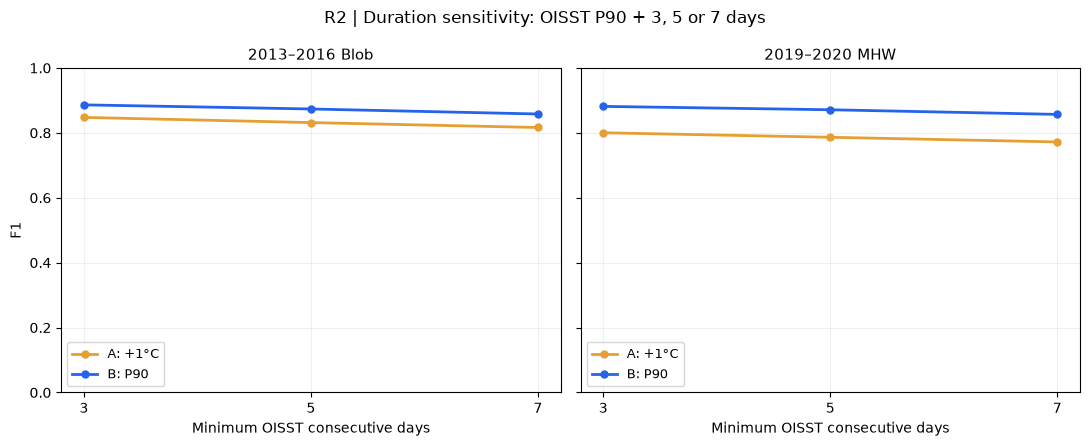

In [61]:
# the reference duration changes; GDP Models A and B stay at their original thresholds.
duration_records=[]
def detect_mhw_duration(exceedance, minimum_days):
    complete=(exceedance.rolling(time=minimum_days,min_periods=minimum_days).sum()==minimum_days)
    result=xr.zeros_like(exceedance,dtype=bool)
    for offset in range(minimum_days):
        result=result | complete.shift(time=-offset,fill_value=False)
    return result

for days in (3,5,7):
    blob_ref=detect_mhw_duration(oisst_exceedance.sel(time=slice("2013-01-01","2016-12-31")),days)
    late_ref=detect_mhw_duration(oisst_exceedance.sel(time=slice("2019-01-01","2020-12-31")),days)
    duration_ref=xr.concat([blob_ref,late_ref],dim="time").sortby("time")
    matched=duration_ref.sel(time=xr.DataArray(rq1_sens["date"].to_numpy(),dims="sample"),
       **{event_lat:xr.DataArray(rq1_sens["lat"].to_numpy(),dims="sample"),
          event_lon:xr.DataArray(np.mod(rq1_sens["lon"].to_numpy(),360),dims="sample")},method="nearest")
    truth=matched.to_numpy().astype(bool)
    for event in rq1_sens.event.unique():
        subset=rq1_sens.event.eq(event).to_numpy()
        for model in ("A","B"):
            duration_records.append({"event":event,"model":model,"minimum_days":days,
                "F1":f1_score(truth[subset],rq1_sens.loc[subset,f"{model}_fixed"],zero_division=0)})
duration_robustness=pd.DataFrame(duration_records)

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4.5), sharey=True
)

events = ["2013–2016 Blob", "2019–2020 MHW"]

model_styles = {
    "A": {"color": "#E69F33", "label": "A: +1°C"},
    "B": {"color": "#2563EB", "label": "B: P90"}
}

for ax, event in zip(axes, events):
    part = duration_robustness[
        duration_robustness["event"] == event
    ]

    for model in ["A", "B"]:
        model_data = (
            part[part["model"] == model]
            .sort_values("minimum_days")
        )

        ax.plot(
            model_data["minimum_days"],
            model_data["F1"],
            marker="o",
            linewidth=2,
            markersize=5,
            color=model_styles[model]["color"],
            label=model_styles[model]["label"]
        )

    ax.set_title(event, fontsize=11)
    ax.set_xlabel("Minimum OISST consecutive days")
    ax.set_xticks([3, 5, 7])
    ax.set_ylim(0, 1.0)
    ax.grid(alpha=0.2)
    ax.legend(loc="lower left", fontsize=9)

axes[0].set_ylabel("F1")

fig.suptitle(
    "R2 | Duration sensitivity: OISST P90 + 3, 5 or 7 days",
    fontsize=12
)

fig.tight_layout()

fig.savefig(
    rq1_output / "Figure_1_12_duration_robustness.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 16. Model B Threshold x GDP Persistence Grid (**Figure 1.13** in Final Report)
One observation per drifter per calendar day, chosen closest to noon. The 2013–2016 period is used to select a parameter combination; 2019–2020 is held out. This grid changes GDP detector persistence, unlike Figure 1.12 which changes OISST reference duration.

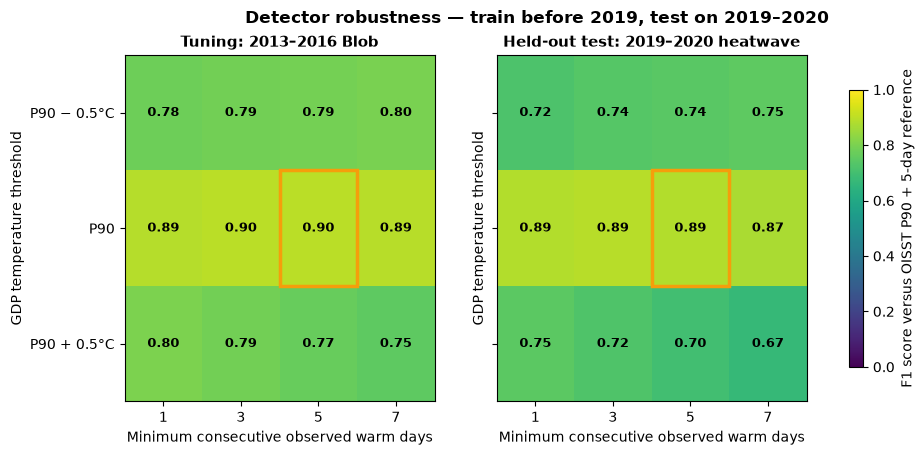

P90 / 5-day F1 — development: 0.896
P90 / 5-day F1 — held-out: 0.886
Best development configuration: P90 5


In [63]:
# reuse reconstructed drifter IDs from the earlier coverage section.
from matplotlib.patches import Rectangle
if "drifter_id" not in gdp.columns:
    raise RuntimeError("Figure 1.13 needs drifter IDs in gdp. Check the earlier ID reconstruction section.")
heat_daily=rq1_sens.copy()
if "drifter_id" not in heat_daily.columns:
    raise RuntimeError("Drifter ID column was lost while preparing the sensitivity sample")
heat_daily["noon_distance"]=(pd.to_datetime(heat_daily.time)-(
    heat_daily.date+pd.Timedelta(hours=12))).abs()
heat_daily=heat_daily.sort_values("noon_distance").drop_duplicates(["drifter_id","date"])
heat_daily=heat_daily.sort_values(["drifter_id","date"]).reset_index(drop=True)
heat_daily["P85"] = heat_daily["p85_c"]
heat_daily["P90"] = heat_daily["historical_p90"]
heat_daily["P95"] = heat_daily["p95_c"]
consecutive=heat_daily.groupby("drifter_id")["date"].diff().eq(pd.Timedelta(days=1)).to_numpy()

def persistent_flags(above, minimum_days):
    above=np.asarray(above,dtype=bool)
    if minimum_days==1:return above
    run_start=(~above)|(~consecutive)
    run_id=np.cumsum(run_start)
    length=pd.Series(above.astype("int8")).groupby(run_id,sort=False).transform("sum").to_numpy()
    return above & (length>=minimum_days)

heat_train = heat_daily.date.dt.year.between(2013, 2016).to_numpy()
heat_test = heat_daily.date.dt.year.between(2019, 2020).to_numpy()

truth = heat_daily.ref_fixed.to_numpy(dtype=bool)

threshold_names = ["P90 − 0.5°C", "P90", "P90 + 0.5°C"]
threshold_offsets = [-0.5, 0.0, 0.5]
duration_choices = [1, 3, 5, 7]

train_scores = np.full((3, 4), np.nan)
test_scores = np.full((3, 4), np.nan)

for i, offset in enumerate(threshold_offsets):
    threshold = heat_daily["historical_p90"].to_numpy() + offset

    for j, days in enumerate(duration_choices):
        predicted = persistent_flags(
            heat_daily["sst_c"].to_numpy() > threshold,
            days
        )

        train_scores[i, j] = f1_score(
            truth[heat_train],
            predicted[heat_train],
            zero_division=0
        )

        test_scores[i, j] = f1_score(
            truth[heat_test],
            predicted[heat_test],
            zero_division=0
        )

# Plot two side-by-side heatmaps
fig, axes = plt.subplots(
    1, 2, figsize=(11, 4.5), sharey=True
)

titles = [
    "Tuning: 2013–2016 Blob",
    "Held-out test: 2019–2020 heatwave"
]

for ax, scores, title in zip(
    axes,
    (train_scores, test_scores),
    titles
):
    im = ax.imshow(
        scores,
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="auto"
    )

    ax.set_title(title, fontsize=11, fontweight="bold")

    ax.set_xticks(range(4))
    ax.set_xticklabels(duration_choices)

    ax.set_yticks(range(3))
    ax.set_yticklabels(threshold_names)

    ax.set_xlabel("Minimum consecutive observed warm days")
    ax.set_ylabel("GDP temperature threshold")

    # Show F1 scores inside cells
    for (r, c), value in np.ndenumerate(scores):
        ax.text(
            c, r,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            color="black" if value > 0.5 else "white"
        )

    # Highlight P90 / 5 days
    selected = Rectangle(
        (1.5, 0.5),
        1, 1,
        fill=False,
        edgecolor="#F59E0B",
        linewidth=2.5
    )
    ax.add_patch(selected)

fig.colorbar(
    im,
    ax=axes,
    label="F1 score versus OISST P90 + 5-day reference",
    shrink=0.8
)

fig.suptitle(
    "Detector robustness — train before 2019, test on 2019–2020",
    fontsize=12,
    fontweight="bold"
)

fig.savefig(
    rq1_output / "Figure_1_13_threshold_duration_grid.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

print("P90 / 5-day F1 — development:",
      round(train_scores[1, 2], 3))
print("P90 / 5-day F1 — held-out:",
      round(test_scores[1, 2], 3))

print("Best development configuration:",
      threshold_names[np.unravel_index(
          np.nanargmax(train_scores),
          train_scores.shape
      )[0]],
      duration_choices[np.unravel_index(
          np.nanargmax(train_scores),
          train_scores.shape
      )[1]])

## 17. Threshold tuning and temporal development
Use the Blob period for development and 2019–2020 MHW for testing. This is a temporal holdout, not an independent external validation.

In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score

validation = gdp.copy()

validation["time"] = pd.to_datetime(validation["time"], utc=True)

# use the same valid observations for both models
validation = validation.dropna(
    subset=["sst_c", "historical_mean", "historical_p90", "oisst_mhw"]
)

development = validation[
    validation["time"].dt.year.between(2013, 2016)
].copy()

test = validation[
    validation["time"].dt.year.between(2019, 2020)
].copy()

print("Development observations:", len(development))
print("Test observations:", len(test))

Development observations: 534212
Test observations: 291531


### Select a detector on the development period

In [65]:
def evaluate_detector(data, model):
    actual = data["oisst_mhw"].astype(bool)

    if model == "Model A":
        predicted = data["sst_c"] > data["historical_mean"] + 1.0
    elif model == "Model B":
        predicted = data["sst_c"] > data["historical_p90"]
    else:
        raise ValueError("Unknown model")

    return {
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0)
    }

development_results = pd.DataFrame({
    model: evaluate_detector(development, model)
    for model in ["Model A", "Model B"]
}).T

print(development_results.round(4))

         Precision  Recall      F1
Model A     0.7360  0.9559  0.8316
Model B     0.8003  0.9616  0.8736


In [66]:
selected_model = development_results["F1"].idxmax()

### Evaluate the selected detector on 2019-2020 MHW

In [67]:
test_results = evaluate_detector(test, selected_model)

print("Selected detector:", selected_model)
print("Development F1:", round(
    development_results.loc[selected_model, "F1"], 4
))
print("Test F1:", round(test_results["F1"], 4))

Selected detector: Model B
Development F1: 0.8736
Test F1: 0.8712


## 18. Tune the Model A anomaly threshold
Compare candidate mean + k thresholds on the 2013–2016 development period.

In [68]:
# thresholds for tuning the GDP Model B exceedance detector
thresholds = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]

tuning_results = []

actual = development["oisst_mhw"].astype(bool)

for k in thresholds:
    predicted = (
        development["sst_c"]
        > development["historical_mean"] + k
    )

    tuning_results.append({
        "Threshold_C": k,
        "Precision": precision_score(actual, predicted),
        "Recall": recall_score(actual, predicted),
        "F1": f1_score(actual, predicted)
    })

tuning_df = pd.DataFrame(tuning_results)

print(tuning_df.round(4))


   Threshold_C  Precision  Recall      F1
0         0.50     0.6071  0.9962  0.7545
1         0.75     0.6656  0.9850  0.7944
2         1.00     0.7360  0.9559  0.8316
3         1.25     0.7997  0.8868  0.8410
4         1.50     0.8532  0.7743  0.8118
5         1.75     0.9052  0.6396  0.7496
6         2.00     0.9455  0.4910  0.6463


In [69]:
# find the best threshold based on the highest F1 score
best_index = tuning_df["F1"].idxmax()
best_k = tuning_df.loc[best_index, "Threshold_C"]

print("Best threshold:", best_k, "°C")
print("Development F1:", tuning_df.loc[best_index, "F1"])


Best threshold: 1.25 °C
Development F1: 0.841003082718642


### Evaluate the selected threshold on the 2019-2020 MHW

In [70]:
actual_test = test["oisst_mhw"].astype(bool)

predicted_test = (
    test["sst_c"]
    > test["historical_mean"] + best_k
)

test_precision = precision_score(actual_test, predicted_test)
test_recall = recall_score(actual_test, predicted_test)
test_f1 = f1_score(actual_test, predicted_test)

print("Selected threshold:", best_k)
print("2019–2020 Precision:", round(test_precision, 4))
print("2019–2020 Recall:", round(test_recall, 4))
print("2019–2020 F1:", round(test_f1, 4))


Selected threshold: 1.25
2019–2020 Precision: 0.7882
2019–2020 Recall: 0.8097
2019–2020 F1: 0.7988


### Compare the tuned threshold with the original P90 detector

In [71]:
def score_model(actual, predicted):
    return {
        "Precision": precision_score(actual, predicted),
        "Recall": recall_score(actual, predicted),
        "F1": f1_score(actual, predicted)
    }

comparison = pd.DataFrame({
    "Tuned mean + k": score_model(
        actual_test,
        predicted_test
    ),
    "Original P90": score_model(
        actual_test,
        test["sst_c"] > test["historical_p90"]
    )
}).T

print(comparison.round(4))

                Precision  Recall      F1
Tuned mean + k     0.7882  0.8097  0.7988
Original P90       0.8078  0.9453  0.8712


### Figure: Model A threshold tuning (**Figure 1.14** in the Final Report)

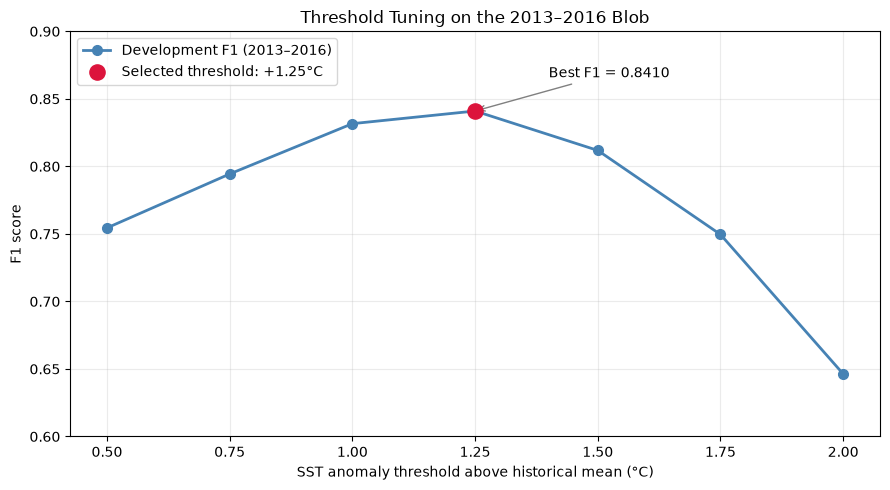

In [72]:
# best threshold from the development period
best_row = tuning_df.loc[tuning_df["F1"].idxmax()]
best_k = best_row["Threshold_C"]
best_f1 = best_row["F1"]

plt.figure(figsize=(9, 5))

# plot F1 across candidate thresholds
plt.plot(
    tuning_df["Threshold_C"],
    tuning_df["F1"],
    marker="o",
    linewidth=2,
    markersize=7,
    color="steelblue",
    label="Development F1 (2013–2016)"
)

# highlight optimal threshold
plt.scatter(
    best_k,
    best_f1,
    color="crimson",
    s=120,
    zorder=5,
    label=f"Selected threshold: +{best_k:.2f}°C"
)

plt.annotate(
    f"Best F1 = {best_f1:.4f}",
    xy=(best_k, best_f1),
    xytext=(best_k + 0.15, best_f1 + 0.025),
    arrowprops=dict(arrowstyle="->", color="gray"),
    fontsize=10
)

plt.xlabel("SST anomaly threshold above historical mean (°C)")
plt.ylabel("F1 score")
plt.title("Threshold Tuning on the 2013–2016 Blob")

plt.xticks(tuning_df["Threshold_C"])
plt.ylim(0.6, 0.9)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../figures/rq1_threshold_tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 19. Summary
This notebook produces the GDP-versus-OISST detection comparisons, monthly and spatial visualisations, confusion matrices, and Model A threshold-tuning results.

In the final report, this notebook contains the data used to formulate **Research Question 1**

Figures included:

1.1 Confusion Matrices

1.2 - 1.3 Tables (Performance statistics and Event-specific F1 scores for Model A and B)

1.4 Monthly detection rate graph

1.5 Spatial maps for October 2014 and September 2019

1.7 Annual mean SST and estimated linear trend

1.8 - 1.9 Model B's sensitivity test on fixed/adjusted OISST reference

1.10 Model B's detection performance on fixed/adjusted OISST

1.11 Robustness check of Model B's detection performance

1.12 Duration robustness for Model A and B

1.13 Threshold duration grid

1.14 Threshold tuning and temporal generalisation